# 04. 영상 분류기 파인튜닝

02에서 만든 DataLoader와 03에서 준비한 (freeze된) `r3d_18`을 합쳐서 실제로 학습을 돌린다.
구조는 Food101 파인튜닝 때와 동일하다: `train_one_epoch` + `evaluate` 루프를 돌리면서
loss/accuracy를 기록하고, 가장 좋은 val accuracy에서 체크포인트를 저장한다.

**GPU 메모리 안내**: RTX 2060(6GB) 기준 `batch_size=4`, `num_frames=16`, `112x112` 해상도면
여유 있게 들어간다. OOM이 나면 `batch_size`를 먼저 줄이고, 그래도 안 되면 `num_frames`를 줄인다.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd()))

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision.models.video import r3d_18, R3D_18_Weights

from video_utils import VideoClipDataset

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEVICE)


device: cuda


## 4-1. 데이터 / 모델 준비 (01~03 노트북 내용을 한 셀로 재구성)

In [2]:
DATA_DIR = Path("data/UCF101_subset")
NUM_FRAMES, CLIP_SIZE, BATCH_SIZE = 16, 112, 4

CLASSES = sorted(p.name for p in (DATA_DIR / "train").iterdir() if p.is_dir())
class_to_idx = {c: i for i, c in enumerate(CLASSES)}


def list_split(split):
    paths, labels = [], []
    for cls in CLASSES:
        for p in sorted((DATA_DIR / split / cls).glob("*.avi")):
            paths.append(p)
            labels.append(class_to_idx[cls])
    return paths, labels


train_paths, train_labels = list_split("train")
val_paths, val_labels = list_split("val")

train_loader = DataLoader(
    VideoClipDataset(train_paths, train_labels, NUM_FRAMES, CLIP_SIZE),
    batch_size=BATCH_SIZE, shuffle=True, num_workers=2,
)
val_loader = DataLoader(
    VideoClipDataset(val_paths, val_labels, NUM_FRAMES, CLIP_SIZE),
    batch_size=BATCH_SIZE, shuffle=False, num_workers=2,
)

model = r3d_18(weights=R3D_18_Weights.KINETICS400_V1)
model.fc = nn.Linear(model.fc.in_features, len(CLASSES))
for name, param in model.named_parameters():
    param.requires_grad = name.startswith("layer4") or name.startswith("fc")
model = model.to(DEVICE)


## 4-2. 학습/평가 루프

In [3]:
import time

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    (p for p in model.parameters() if p.requires_grad), lr=1e-4
)


def run_epoch(loader, train: bool):
    model.train(train)
    total_loss, total_correct, total_n = 0.0, 0, 0
    torch.set_grad_enabled(train)
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        if train:
            optimizer.zero_grad()
        out = model(xb)
        loss = criterion(out, yb)
        if train:
            loss.backward()
            optimizer.step()
        total_loss += loss.item() * xb.size(0)
        total_correct += (out.argmax(1) == yb).sum().item()
        total_n += xb.size(0)
    torch.set_grad_enabled(True)
    return total_loss / total_n, total_correct / total_n


In [4]:
EPOCHS = 8
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
best_val_acc = 0.0
CKPT_PATH = Path("checkpoints/r3d18_ucf101_subset.pt")
CKPT_PATH.parent.mkdir(exist_ok=True)

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    tr_loss, tr_acc = run_epoch(train_loader, train=True)
    val_loss, val_acc = run_epoch(val_loader, train=False)
    history["train_loss"].append(tr_loss)
    history["train_acc"].append(tr_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(
            {"model_state": model.state_dict(), "classes": CLASSES},
            CKPT_PATH,
        )

    print(
        f"epoch {epoch:02d}/{EPOCHS} | "
        f"train loss {tr_loss:.3f} acc {tr_acc:.2f} | "
        f"val loss {val_loss:.3f} acc {val_acc:.2f} | "
        f"{time.time()-t0:.1f}s"
    )

print(f"best val acc: {best_val_acc:.2f} (checkpoint: {CKPT_PATH})")


epoch 01/8 | train loss 1.052 acc 0.74 | val loss 0.089 acc 1.00 | 10.6s
epoch 02/8 | train loss 0.249 acc 0.98 | val loss 0.057 acc 1.00 | 10.0s
epoch 03/8 | train loss 0.184 acc 0.96 | val loss 0.046 acc 1.00 | 10.0s
epoch 04/8 | train loss 0.112 acc 0.99 | val loss 0.027 acc 1.00 | 10.0s
epoch 05/8 | train loss 0.068 acc 1.00 | val loss 0.019 acc 1.00 | 10.0s
epoch 06/8 | train loss 0.104 acc 1.00 | val loss 0.072 acc 0.97 | 10.0s
epoch 07/8 | train loss 0.084 acc 1.00 | val loss 0.018 acc 1.00 | 10.0s
epoch 08/8 | train loss 0.064 acc 1.00 | val loss 0.011 acc 1.00 | 10.1s
best val acc: 1.00 (checkpoint: checkpoints/r3d18_ucf101_subset.pt)


## 4-3. 학습 곡선 확인

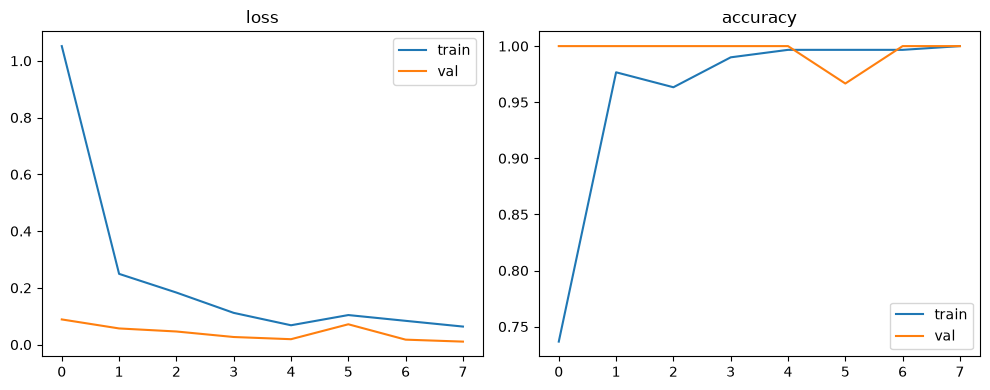

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(history["train_loss"], label="train")
axes[0].plot(history["val_loss"], label="val")
axes[0].set_title("loss"); axes[0].legend()
axes[1].plot(history["train_acc"], label="train")
axes[1].plot(history["val_acc"], label="val")
axes[1].set_title("accuracy"); axes[1].legend()
plt.tight_layout()
plt.show()


5개 클래스 x 클래스당 12개 학습 영상이라는 아주 작은 데이터셋이라 val accuracy가 들쭉날쭉할 수
있다. 그래도 Food101 때처럼 "사전학습 모델의 마지막 블록만 살짝 손대는" 전이학습 패턴이
영상에서도 그대로 통한다는 걸 확인하는 게 이 노트북의 목적이다.

다음 노트북에서 저장된 체크포인트로 새 영상에 대해 추론을 해본다.